# Titanic Mean Encoding Tutorial

Mean encoding replaces each category with its observed mean of the target. For Titanic, the binary target is `survived`, so a category value becomes the survival rate learned from the training data.

This tutorial covers:
- cleaning and inspecting the Titanic data;
- deriving a cabin deck from the high-cardinality cabin field;
- calculating category means and counts;
- preventing target leakage with a training-only split;
- smoothing rare categories;
- handling missing and unseen categories; and
- comparing mean encoding with one-hot encoding in a logistic regression model.

## 1. Load the data and required libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

np.random.seed(42)
sns.set_theme(style="whitegrid")

csv_path = Path("titanic.csv")
if not csv_path.exists():
    csv_path = Path("encoding/titanic.csv")
    
    
df = pd.read_csv(csv_path)
print(f"Loaded {csv_path}")
print("Shape:", df.shape)
df.head()

Loaded titanic.csv
Shape: (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,24160,211.3375,B5,S,2,?,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.55,C22 C26,S,11,?,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,113781,151.55,C22 C26,S,?,135,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"


## 2. Inspect the data

The local dataset contains passenger-level information and the binary target `survived`. We replace textual question marks, commonly found in older Titanic exports, with proper missing values before analysis.

In [2]:
df.info()
print("\nMissing values before cleaning:")
display(df.replace("?", np.nan).isna().sum().sort_values(ascending=False))
print("\nTarget balance:")
display(df["survived"].value_counts().rename(index={0:"died", 1:"survived"}))
display(df.describe(include="all").transpose().head(14))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   pclass     1309 non-null   int64 
 1   survived   1309 non-null   int64 
 2   name       1309 non-null   object
 3   sex        1309 non-null   object
 4   age        1309 non-null   object
 5   sibsp      1309 non-null   int64 
 6   parch      1309 non-null   int64 
 7   ticket     1309 non-null   object
 8   fare       1309 non-null   object
 9   cabin      1309 non-null   object
 10  embarked   1309 non-null   object
 11  boat       1309 non-null   object
 12  body       1309 non-null   object
 13  home.dest  1309 non-null   object
dtypes: int64(4), object(10)
memory usage: 143.3+ KB

Missing values before cleaning:


body         1188
cabin        1014
boat          823
home.dest     564
age           263
embarked        2
fare            1
pclass          0
survived        0
name            0
sex             0
sibsp           0
parch           0
ticket          0
dtype: int64


Target balance:


survived
died        809
survived    500
Name: count, dtype: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pclass,1309.0,NaN,NaN,NaN,2.294882,0.837836,1.0,2.0,3.0,3.0,3.0
survived,1309.0,NaN,NaN,NaN,0.381971,0.486055,0.0,0.0,0.0,1.0,1.0
name,1309,1307,"Connolly, Miss. Kate",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,1309,2,male,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1309,99,?,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sibsp,1309.0,NaN,NaN,NaN,0.498854,1.041658,0.0,0.0,0.0,1.0,8.0
parch,1309.0,NaN,NaN,NaN,0.385027,0.86556,0.0,0.0,0.0,0.0,9.0
ticket,1309,929,CA. 2343,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare,1309,282,8.05,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cabin,1309,187,?,1014,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Replace '?' placeholders and create a cabin-deck representation
data = df.replace("?", np.nan).copy()
data["cabin"] = data["cabin"].astype("string")
data["cabin_deck"] = data["cabin"].str[0].fillna("Missing")
data["embarked"] = data["embarked"].fillna("C")
data["pclass"] = data["pclass"].astype("object")
data["age"] = pd.to_numeric(data["age"], errors="coerce")
data["fare"] = pd.to_numeric(data["fare"], errors="coerce")

print("Cabin decks:", sorted(data["cabin_deck"].unique()))
display(data[["pclass", "sex", "cabin", "cabin_deck", "embarked", "survived"]].head())

Cabin decks: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Missing', 'T']


,pclass,sex,cabin,cabin_deck,embarked,survived
0,1,female,B5,B,S,1
1,1,male,C22 C26,C,S,1
2,1,female,C22 C26,C,S,0
3,1,male,C22 C26,C,S,0
4,1,female,C22 C26,C,S,0


### Why derive cabin deck?

The raw cabin variable contains hundreds of rare combinations or individual cabin identifiers, making mean encoding especially unstable. The first letter groups cabins into decks and preserves useful information while reducing cardinality. The missing deck is treated explicitly as `Missing`, not discarded.

## 3. Choose features and examine category survival rates

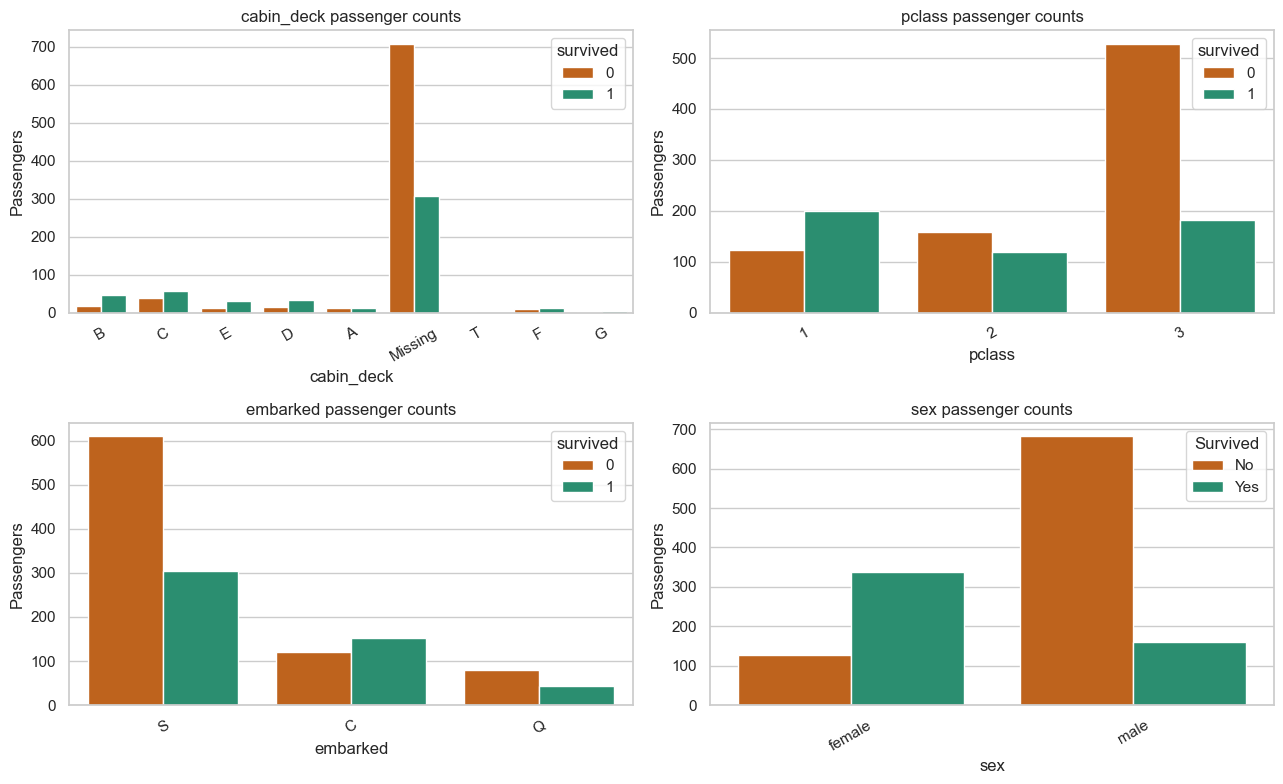

In [5]:
encode_vars = ["cabin_deck", "pclass", "embarked"]
feature_cols = ["cabin_deck", "pclass", "embarked", "sex", "age", "sibsp", "parch", "fare"]
X = data[feature_cols].copy()
y = data["survived"].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), encode_vars + ["sex"]):
    sns.countplot(data=data, x=col, hue="survived", ax=ax, palette={0:"#d95f02", 1:"#1b9e77"})
    ax.set_title(f"{col} passenger counts")
    ax.set_xlabel(col)
    ax.set_ylabel("Passengers")
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


cabin_deck - training category statistics on the full dataset (exploratory only):


,count,sum,survival_rate
cabin_deck,,,
T,1,0,0.000000
Missing,1014,307,0.302761
A,22,11,0.500000
G,5,3,0.600000
C,94,57,0.606383
F,21,13,0.619048
D,46,32,0.695652
B,65,47,0.723077
E,41,30,0.731707



pclass - training category statistics on the full dataset (exploratory only):


,count,sum,survival_rate
pclass,,,
3,709,181,0.255289
2,277,119,0.429603
1,323,200,0.619195



embarked - training category statistics on the full dataset (exploratory only):


,count,sum,survival_rate
embarked,,,
S,914,304,0.332604
Q,123,44,0.357724
C,272,152,0.558824


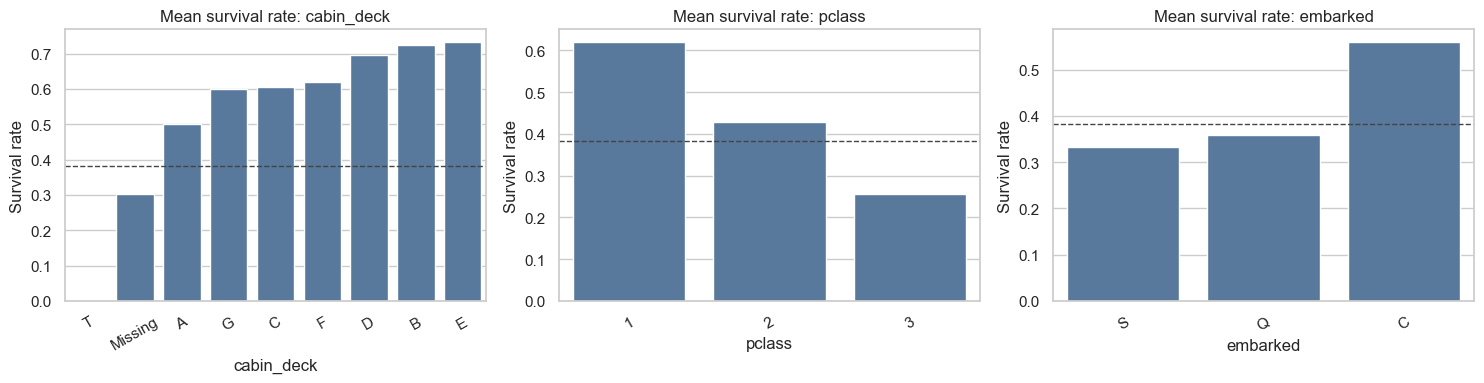

In [6]:
category_summary = {}
for col in encode_vars:
    summary = (data.groupby(col, dropna=False)["survived"]
               .agg(["count", "sum", "mean"])
               .rename(columns={"mean": "survival_rate"})
               .sort_values("survival_rate"))
    category_summary[col] = summary
    print(f"\n{col} - training category statistics on the full dataset (exploratory only):")
    display(summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, encode_vars):
    summary = category_summary[col].reset_index()
    sns.barplot(data=summary, x=col, y="survival_rate", ax=ax, color="#4C78A8")
    ax.axhline(data["survived"].mean(), color="#444444", linestyle="--", linewidth=1)
    ax.set_title(f"Mean survival rate: {col}")
    ax.set_ylabel("Survival rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

The dashed line is the overall survival rate. Category means above the line have a higher-than-average survival rate; means below it have a lower-than-average rate. These exploratory full-data statistics are descriptive; the model mapping below is learned from training rows only.

## 4. Understand the basic mean encoder

For category $c$, the ordinary mean encoding value is:

$$\hat{y}_c = 
rac{1}{n_c}\sum_{i: x_i=c} y_i$$

It is the survival rate inside that category. Rare categories can be highly unstable, so we also demonstrate smoothing.

In [7]:
class MeanTargetEncoder:
    """Leakage-safe mean target encoder for a list of categorical columns."""
    def __init__(self, variables, smoothing=10.0, unseen="global"):
        self.variables = list(variables)
        self.smoothing = float(smoothing)
        self.unseen = unseen

    def fit(self, X_fit, y_fit):
        y_fit = pd.Series(np.asarray(y_fit), index=X_fit.index, name="target")
        frame = X_fit[self.variables].copy().astype("string").fillna("Missing")
        frame["target"] = y_fit
        self.global_mean_ = float(y_fit.mean())
        self.encoder_dict_ = {}
        for col in self.variables:
            stats = frame.groupby(col)["target"].agg(["count", "sum", "mean"])
            smoothed = ((stats["count"] * stats["mean"] + self.smoothing * self.global_mean_) /
                        (stats["count"] + self.smoothing))
            self.encoder_dict_[col] = smoothed.to_dict()
        return self

    def transform(self, X_transform):
        result = X_transform.copy()
        for col in self.variables:
            values = result[col].astype("string")
            mapping = self.encoder_dict_[col]
            values = values.fillna("Missing")
            result[col] = values.map(mapping).fillna(self.global_mean_)
        return result

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

plain_encoder = MeanTargetEncoder(encode_vars, smoothing=0.0)
plain_encoder.fit(X_train, y_train)
train_plain = plain_encoder.transform(X_train)
test_plain = plain_encoder.transform(X_test)

print("Training-only cabin mappings:")
for key, value in sorted(plain_encoder.encoder_dict_["cabin_deck"].items(), key=lambda item: str(item[0])):
    print(f"  {key}: {value:.4f}")
print("Global training survival rate:", round(plain_encoder.global_mean_, 4))
train_plain[encode_vars].head()

Train shape: (916, 8) Test shape: (393, 8)
Training-only cabin mappings:
  A: 0.5000
  B: 0.6667
  C: 0.5692
  D: 0.7143
  E: 0.7143
  F: 0.7500
  G: 0.6667
  Missing: 0.3105
  T: 0.0000
Global training survival rate: 0.3821


,cabin_deck,pclass,embarked
306,0.714286,0.592105,0.330684
927,0.310490,0.269461,0.572165
642,0.310490,0.269461,0.330684
1294,0.310490,0.269461,0.330684
1015,0.310490,0.269461,0.330684


## 5. Inspect smooth mean encoding

The smoothing formula below pulls estimates for categories with few rows toward the overall training survival rate. Larger smoothing values shrink more strongly:

$$
rac{n_c 	imes \hat{y}_c + lpha 	imes \hat{y}_{global}}{n_c + lpha}$$

In [8]:
smooth_encoder = MeanTargetEncoder(encode_vars, smoothing=10.0)
smooth_encoder.fit(X_train, y_train)
train_encoded = smooth_encoder.transform(X_train)
test_encoded = smooth_encoder.transform(X_test)

comparison = pd.DataFrame({"original": X_train["cabin_deck"]}).join(
    train_encoded["cabin_deck"].rename("mean_encoded")
)
display(comparison.head(12))

stats = X_train.assign(cabin=X_train["cabin_deck"], survived=y_train).groupby("cabin")["survived"].agg(["count", "mean"])
stats["smoothed"] = stats.apply(lambda r: (r["count"] * r["mean"] + 10.0 * y_train.mean()) / (r["count"] + 10.0), axis=1)
stats.sort_values("smoothed")

,original,mean_encoded
306,D,0.640466
927,Missing,0.311477
642,Missing,0.311477
1294,Missing,0.311477
1015,Missing,0.311477
220,B,0.614927
985,Missing,0.311477
356,Missing,0.311477
538,Missing,0.311477
828,Missing,0.311477


,count,mean,smoothed
cabin,,,
Missing,715,0.310490,0.311477
T,1,0.000000,0.347360
G,3,0.666667,0.447766
A,16,0.500000,0.454652
C,65,0.569231,0.544279
F,8,0.750000,0.545609
B,45,0.666667,0.614927
E,28,0.714286,0.626867
D,35,0.714286,0.640466


Smoothing changes little when a category has many observations. It can change estimates substantially for rare categories such as decks represented by only a few passengers.

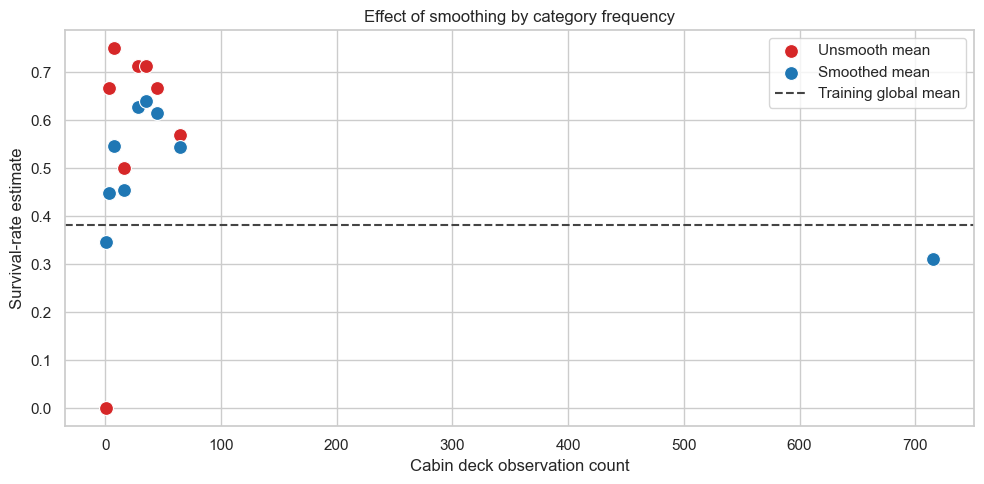

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_data = stats.reset_index().sort_values("count")
sns.scatterplot(data=plot_data, x="count", y="mean", s=100, color="#d62728", label="Unsmooth mean")
sns.scatterplot(data=plot_data, x="count", y="smoothed", s=100, color="#1f77b4", label="Smoothed mean")
ax.axhline(y_train.mean(), color="#444444", linestyle="--", label="Training global mean")
ax.set_xlabel("Cabin deck observation count")
ax.set_ylabel("Survival-rate estimate")
ax.set_title("Effect of smoothing by category frequency")
ax.legend()
plt.tight_layout()
plt.show()

### Written interpretation

Rare categories move toward the horizontal training mean, while frequent categories stay close to their observed survival rates. This reduces the impact of one or two unusually lucky or unlucky rare observations.

## 6. Encode the selected features safely

The category mapping is fitted only on `X_train` and then applied to `X_test`. Every unseen category—and every missing category in a column—is replaced by the training global survival rate, preventing a new category from crashing or receiving an arbitrarily large value.

In [10]:
# Demonstrate unseen-category behavior without using test target information in fitting.
demo = pd.DataFrame({"cabin_deck": ["Missing", "Unknown future deck", "B"],
                     "pclass": ["3", "1", "2"],
                     "embarked": ["S", "C", "Q"]})
display(smooth_encoder.transform(demo))

# Convert only the three target-encoded categorical columns; retain the rest of the model features.
X_train_encoded = train_encoded.copy()
X_test_encoded = test_encoded.copy()
for col in encode_vars:
    X_train_encoded[col] = X_train_encoded[col].astype(float)
    X_test_encoded[col] = X_test_encoded[col].astype(float)

numeric_cols = ["age", "sibsp", "parch", "fare"]
display(pd.concat([X_train[["cabin_deck", "pclass", "embarked"]].iloc[:5],
                   X_train_encoded[encode_vars].iloc[:5]], axis=1))

,cabin_deck,pclass,embarked
0,0.311477,0.271665,0.331488
1,0.382096,0.583281,0.562848
2,0.614927,0.425487,0.338068


,cabin_deck,pclass,embarked,cabin_deck,pclass,embarked
306,D,1,S,0.640466,0.583281,0.331488
927,Missing,3,C,0.311477,0.271665,0.562848
642,Missing,3,S,0.311477,0.271665,0.331488
1294,Missing,3,S,0.311477,0.271665,0.331488
1015,Missing,3,S,0.311477,0.271665,0.331488


## 7. Visualize raw categories and encoded values

/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_55301/1351140361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No", "Yes"])
/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_55301/1351140361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No", "Yes"])
/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_55301/1351140361.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No", "Yes"])


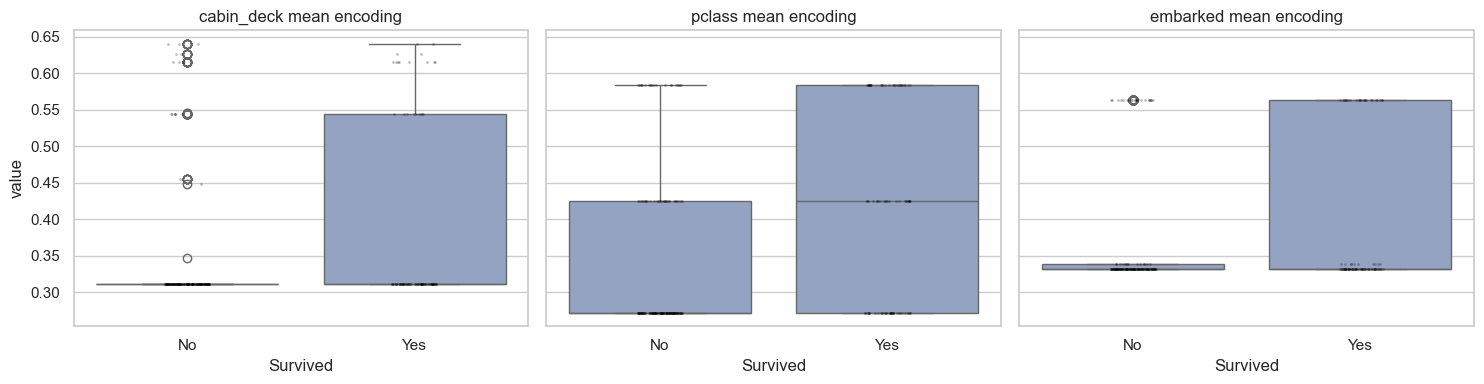

In [11]:
encoded_melt = pd.DataFrame({
    "passenger_class": X_train_encoded["pclass"].astype(float),
    "embarked": X_train_encoded["embarked"].astype(float),
    "cabin_deck": X_train_encoded["cabin_deck"].astype(float),
    "survived": np.asarray(y_train)
}).melt(id_vars="survived", var_name="feature", value_name="mean_encoded_value")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, encode_vars):
    y_values = pd.Series(np.asarray(y_train)).reset_index(drop=True)
    plot_df = pd.DataFrame({"value": X_train_encoded[col].to_numpy(), "survived": y_values.to_numpy()})
    sns.boxplot(data=plot_df, x="survived", y="value", ax=ax, color="#8da0cb")
    sns.stripplot(data=plot_df.sample(min(250, len(plot_df)), random_state=42), x="survived", y="value",
                  ax=ax, color="black", alpha=0.25, size=2)
    ax.set_title(f"{col} mean encoding")
    ax.set_xlabel("Survived")
    ax.set_xticklabels(["No", "Yes"])
plt.tight_layout()
plt.show()

If the encoded distributions for survivors and non-survivors are separated, the category has learned useful target signal. Overlap does not mean the feature is useless; it may combine with other features in a model.

## 8. Compare mean encoding with one-hot encoding

,method,accuracy,ROC-AUC
0,One-hot,0.801527,0.867517
1,Smoothed mean encoding,0.816794,0.871660


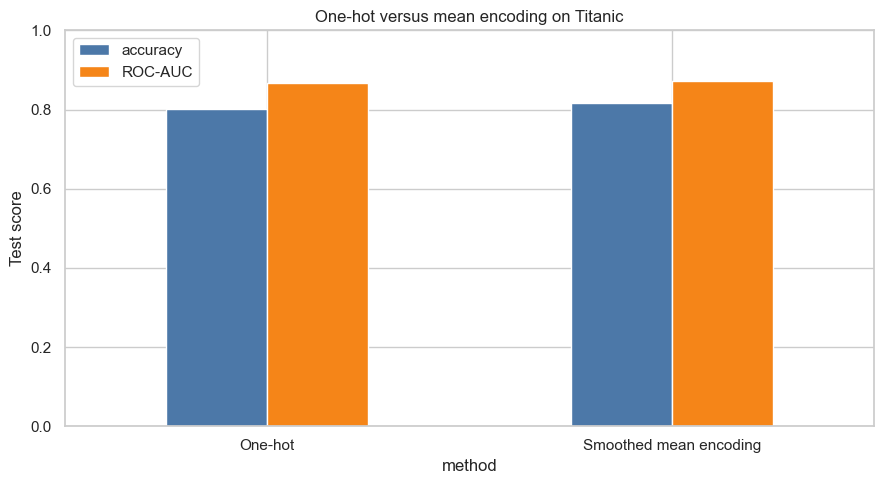

In [12]:
categorical_all = encode_vars + ["sex"]
preprocess_ohe = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
    ]), categorical_all),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols)
])

one_hot_model = Pipeline([
    ("preprocess", preprocess_ohe),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
one_hot_model.fit(X_train, y_train)
ohe_pred = one_hot_model.predict(X_test)
ohe_prob = one_hot_model.predict_proba(X_test)[:, 1]

preprocess_mean = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols),
    ("mean_features", "passthrough", encode_vars)
])
mean_features_train = X_train_encoded.drop(columns=[c for c in ["sex"] if c in X_train_encoded])
mean_features_test = X_test_encoded.drop(columns=[c for c in ["sex"] if c in X_test_encoded])
# Sex remains categorical; add a numeric dummy for this compact comparison.
mean_features_train["sex_female"] = (X_train["sex"] == "female").astype(int)
mean_features_test["sex_female"] = (X_test["sex"] == "female").astype(int)

mean_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
        ("mean_features", "passthrough", encode_vars + ["sex_female"])
    ])),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
mean_model.fit(mean_features_train, y_train)
mean_pred = mean_model.predict(mean_features_test)
mean_prob = mean_model.predict_proba(mean_features_test)[:, 1]

comparison_results = pd.DataFrame({
    "method": ["One-hot", "Smoothed mean encoding"],
    "accuracy": [accuracy_score(y_test, ohe_pred), accuracy_score(y_test, mean_pred)],
    "ROC-AUC": [roc_auc_score(y_test, ohe_prob), roc_auc_score(y_test, mean_prob)],
})
display(comparison_results)

ax = comparison_results.set_index("method")[["accuracy", "ROC-AUC"]].plot.bar(figsize=(9, 5), rot=0, color=["#4C78A8", "#F58518"])
ax.set_ylim(0, 1)
ax.set_ylabel("Test score")
ax.set_title("One-hot versus mean encoding on Titanic")
plt.tight_layout()
plt.show()

Accuracy and ROC-AUC show held-out performance, but one result should not be used to declare the encoder universally superior. Repeated stratified cross-validation is more robust for small changes. Mean encoding is fast and compact; one-hot encoding is more transparent and does not create a direct numeric relationship based on the target.

## 9. Optional Feature-engine implementation

The reference lesson often uses `feature_engine.encoding.MeanEncoder`. Feature-engine is optional here. If it is installed, the following block fits its encoder in the same training-only split; if it is absent, the notebook uses the custom implementation above and prints installation guidance.

In [14]:
try:
    from feature_engine.encoding import MeanEncoder

    fe_encoder = MeanEncoder(variables=encode_vars, unseen="ignore")
    fe_encoder.fit(X_train.astype({c: "object" for c in encode_vars}), y_train)
    print("Feature-engine encoder mappings:")
    print(fe_encoder.encoder_dict_["cabin_deck"])
except ImportError:
    print("feature_engine is not installed in this kernel.")
    print("Optional install: pip install feature-engine")
except Exception as exc:
    print("Feature-engine is installed, but this sample encountered:", type(exc).__name__, str(exc))

feature_engine is not installed in this kernel.
Optional install: pip install feature-engine


## 10. Cross-validation and leakage reminder

In [15]:
# Run unsmoothed and smoothed 5-fold cross-validation using manual train-fold encoders.
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for smoothing in [0.0, 10.0, 50.0]:
    auc_scores = []
    for tr_idx, val_idx in cv.split(X, y):
        X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        enc = MeanTargetEncoder(encode_vars, smoothing=smoothing).fit(X_tr, y_tr)
        X_tr_enc, X_val_enc = enc.transform(X_tr), enc.transform(X_val)
        X_tr_enc["sex_female"] = (X_tr["sex"] == "female").astype(int)
        X_val_enc["sex_female"] = (X_val["sex"] == "female").astype(int)

        numeric = ["age", "sibsp", "parch", "fare"]
        prep = ColumnTransformer([
            ("num", Pipeline([("median", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
            ("encoded", "passthrough", encode_vars + ["sex_female"])
        ])
        fold_model = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000, random_state=42))])
        fold_model.fit(X_tr_enc, y_tr)
        auc_scores.append(roc_auc_score(y_val, fold_model.predict_proba(X_val_enc)[:, 1]))
    print(f"smoothing={smoothing:5.1f}: mean ROC-AUC={np.mean(auc_scores):.4f}, std={np.std(auc_scores):.4f}")

smoothing=  0.0: mean ROC-AUC=0.8416, std=0.0261
smoothing= 10.0: mean ROC-AUC=0.8415, std=0.0264
smoothing= 50.0: mean ROC-AUC=0.8417, std=0.0278


## 11. Practical conclusions

### Strengths
- Compact numeric representation: one feature remains one feature after encoding.
- Can capture target differences effectively when categories have stable sample sizes.
- Works naturally for high-cardinality variables such as cabin decks.

### Risks
- Directly uses the target and can leak validation labels if mappings are fit on the full data.
- Rare categories may memorize small samples.
- Encoded values may be shifted under data drift if category survival patterns change.
- Creates less interpretable category structure for some linear models unless mappings are documented.

### Recommendations for Titanic
- Prefer mean encoding with training-fold fit and smoothing for cabin deck or other high-cardinality engineered features.
- Prefer one-hot encoding for `sex`, `embarked`, and small, stable variables when interpretability matters.
- Treat `Missing` and unseen categories explicitly.
- Try smoothing values by cross-validation rather than selecting the value from held-out labels.

A production implementation should fit the encoder inside each training fold of a cross-validation or modeling pipeline, never fit it on the complete dataset before splitting.